# MCDI505  Sumativa 2  Modelos clásicos (ARIMA / SARIMA)
| | |
|---|---|
| **Estudiante** | Claudio Rodolfo Alarcón Pradenas   |
| **Docente** | Dr. Harvey Jezlid Rosas Quintero |
| **Evaluación** | Sumativa 2 · Semana 2 · Fase 2 (búsqueda y recopilación activa de información) · 15 de octubre de 2026 |
| **Datos:**| data/raw/consumo_electrico_litoral_depurado.csv`|
| **Repositorio (respaldo y reproducibilidad)** | `https://github.com/claudioalarconP/Analisis_de_serie_de_tiempo` |

## Hoja de decisiones

| Criterio | Decisión | Evidencia clave (cifra, prueba o figura) | Alternativa descartada | Consecuencia |
|---|---|---|---|---|
| 1. Estacionariedad y transformaciones | Logaritmo; d = 1, D = 1, s = 12 | Box-Cox λ̂ = 0,004. En log: ADF p = 0,155 y KPSS p ≥ 0,10. Tras ∇∇₁₂: ADF p < 0,001 y KPSS p ≥ 0,10 (Tabla 1, Fig. 2) | Solo ∇₁₂ (ADF p = 0,101); d = 2 (varianza +90 %, ρ1 = −0,425: sobrediferenciación) | Se pronostica en log y se retransforma a GWh con corrección de sesgo |
| 2. Identificación y estimación | M1 (0,1,0)(0,1,1)₁₂, M2 (0,1,1)(0,1,1)₁₂, M3 (1,1,0)(0,1,1)₁₂ y M4 (0,1,0)(1,1,0)₁₂ como lectura alternativa | ACF de w_t solo en 12 (−0,298); PACF en 12 y 24; rezago 1 (−0,256) al descontar el shock de 2020 (Fig. 3, Tabla 2) | Búsqueda automática de órdenes | MA estacionales próximos a −1 (M1–M3); M4 estable (Φ̂1 = −0,311) |
| 3. Selección y comparación | **M4**, modelo de pronóstico | Menores RMSE (4,12) y MAE (3,71 GWh) en 2023; RMSE 43 % menor que el naive estacional (7,26) y 13 % menor que el naive con deriva (Tabla 3, Fig. 4) | M1: menor AIC/BIC (−300,0 / −295,2), pero RMSE ≈ 7,2. M6 con intervención: RMSE ≈ 5,7 | Prima el error fuera de muestra; válido para un solo origen (2023) |
| 4. Diagnóstico de residuos | M4 utilizable con reservas | Ljung-Box p = 0,679 (K = 12) y 0,059 (K = 24); Jarque-Bera p = 0,564; ARCH-LM p = 0,786 (Tabla 4, Fig. 5) | Declarar ruido blanco: K = 24 está próximo al umbral | Intervalos aproximados; vigilar el rezago 24 |

### Reproducibilidad y ejecución

El notebook se ejecuta completo y en orden con *Restart Kernel and Run All*. Requiere Python 3 con `numpy`, `pandas`, `scipy`, `matplotlib` y `statsmodels`; la celda de configuración registra las versiones utilizadas. El único archivo de datos es `consumo_electrico_litoral_depurado.csv`, que se localiza con rutas relativas (junto al notebook o en `data/raw` del proyecto). Se estima con enero de 2015 a diciembre de 2022 y se valida con 2023; los datos de 2024 no participan en la estimación, la selección ni la evaluación, y el código lo verifica con aserciones. Las cifras del texto corresponden a las salidas del propio notebook y se contrastan automáticamente al final de la sección 4.

## 0. Configuración y datos

In [1]:
%matplotlib inline
# Activa explícitamente el backend gráfico del notebook (JupyterLab, VS Code y Colab); sin él, algunas combinaciones
# de ipykernel y matplotlib no muestran la primera figura de la sesión.
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels
import statsmodels.api as sm
from scipy import stats
from IPython.display import display
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch, het_goldfeldquandt
from statsmodels.tools.sm_exceptions import ConvergenceWarning, InterpolationWarning
# No se silencia ningún aviso de forma global: el p de KPSS fuera de tabla se trata localmente (sección 1)
# y los avisos de convergencia se cuentan al estimar (sección 2).

SEMILLA = 505
np.random.seed(SEMILLA)
S, ALFA = 12, 0.05            # período estacional y nivel de significancia
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
                     "axes.titlesize": 11, "legend.fontsize": 8, "axes.spines.top": False, "axes.spines.right": False})
ROJO, AZUL, GRIS, VERDE, NARANJA, MORADO = "#b30338", "#0057b8", "#9e9e9e", "#2e7d32", "#ef6c00", "#6a1b9a"
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 70)

# Cifras de las salidas "Evidencia": se generan desde las variables, nunca se escriben a mano
num = lambda x, d=2: f"{round(float(x), d) + 0.0:.{d}f}".replace(".", ",").replace("-", "−")
pval = lambda p: "< 0,001" if p < 0.001 else num(p, 3)
pct = lambda x, d=1: ("+" if round(x, d) > 0 else "") + num(x, d) + " %"
def evidencia(*lineas):
    print("Evidencia\n" + "\n".join(f"  · {l}" for l in lineas))

# --- Datos: ruta relativa (junto al notebook o en data/, data/raw, data/processed) ---
ARCHIVO = "consumo_electrico_litoral_depurado.csv"
rutas = [Path(*[".."] * n) / sub / ARCHIVO for n in range(4) for sub in (".", "data", "data/raw", "data/processed")]
ruta = next((r for r in rutas if r.exists()), None)
if ruta is None:
    raise FileNotFoundError(f"No se encontró {ARCHIVO} desde {Path.cwd()}. Ubíquelo junto al notebook o en data/, data/raw "
                            f"o data/processed del proyecto. En Google Colab, súbalo al panel Archivos (directorio /content).")
df = pd.read_csv(ruta, parse_dates=["fecha"], index_col="fecha")

# --- Auditoría del índice temporal ---
n_duplicados = int(df.index.duplicated().sum())
meses_faltantes = pd.date_range(df.index.min(), df.index.max(), freq="MS").difference(df.index)
assert df.index.is_monotonic_increasing and n_duplicados == 0 and meses_faltantes.empty, "índice desordenado, duplicado o incompleto"
assert pd.infer_freq(df.index) == "MS", "la frecuencia debe ser mensual"
df.index.freq = "MS"
y = df["consumo_gwh"]
assert y.notna().all() and (y > 0).all(), "la serie debe ser completa y positiva (requisito del logaritmo)"

# --- Partición oficial: 2024 no se utiliza esta semana ---
y_train = y["2015-01":"2022-12"]
y_val   = y["2023-01":"2023-12"]
assert len(y_train) == 96 and len(y_val) == 12 and y_train.index.max() < y_val.index.min()
assert not y_train.index.append(y_val.index).year.isin([2024]).any()

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__} | "
      f"statsmodels {statsmodels.__version__} | matplotlib {matplotlib.__version__}")
print(f"Archivo: {ruta.as_posix()} | {df.shape[0]} filas × {df.shape[1]} columnas | {df.index.min():%Y-%m} a {df.index.max():%Y-%m} | "
      f"frecuencia {df.index.freqstr} | duplicados = {n_duplicados} | meses faltantes = {len(meses_faltantes)}")
print(f"Entrenamiento: {y_train.index.min():%Y-%m} a {y_train.index.max():%Y-%m} ({len(y_train)} obs.)")
print(f"Validación:    {y_val.index.min():%Y-%m} a {y_val.index.max():%Y-%m} ({len(y_val)} obs.) | 2024 excluido")
fmt = lambda col: ", ".join(f"{t:%Y-%m}" for t in df.index[df[col] == 1])
print(f"CSV depurado → imputado: {fmt('imputado')} | atipico_corregido: {fmt('atipico_corregido')} | "
      f"covid: {df.index[df['covid'] == 1].min():%Y-%m} a {df.index[df['covid'] == 1].max():%Y-%m}")

Python 3.12.5 | numpy 2.4.6 | pandas 3.0.3 | scipy 1.18.0 | statsmodels 0.14.6 | matplotlib 3.10.9
Archivo: ../../../data/raw/consumo_electrico_litoral_depurado.csv | 120 filas × 8 columnas | 2015-01 a 2024-12 | frecuencia MS | duplicados = 0 | meses faltantes = 0
Entrenamiento: 2015-01 a 2022-12 (96 obs.)
Validación:    2023-01 a 2023-12 (12 obs.) | 2024 excluido
CSV depurado → imputado: 2016-08, 2019-02, 2022-06 | atipico_corregido: 2017-11 | covid: 2020-03 a 2021-12


`consumo_gwh` es el consumo eléctrico mensual (GWh) del segmento comercial de la Distribuidora Eléctrica del Litoral, que cada diciembre compromete la energía del año siguiente; por eso el horizonte de pronóstico es h = 12 (Universidad Andrés Bello [UNAB], s. f.-a). Se usa el CSV depurado oficial, que ya imputa tres faltantes, corrige noviembre de 2017 e incluye la indicadora `covid` (marzo de 2020 a diciembre de 2021). La auditoría no encontró duplicados, meses faltantes ni valores no positivos. Se estima con 2015–2022, se valida con 2023 y no se usa 2024.

## 1. Análisis de estacionariedad y transformaciones

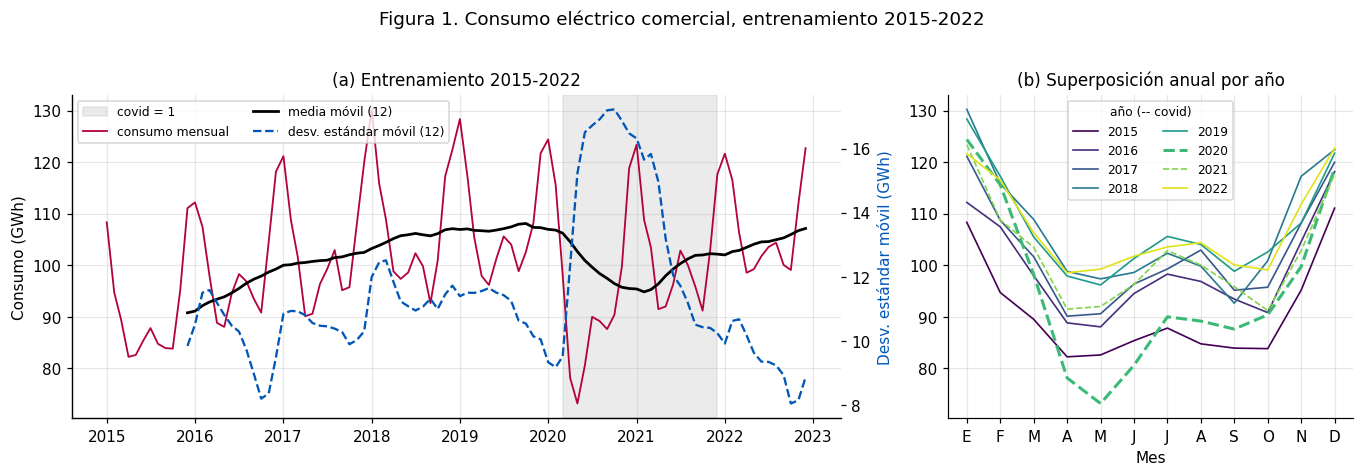

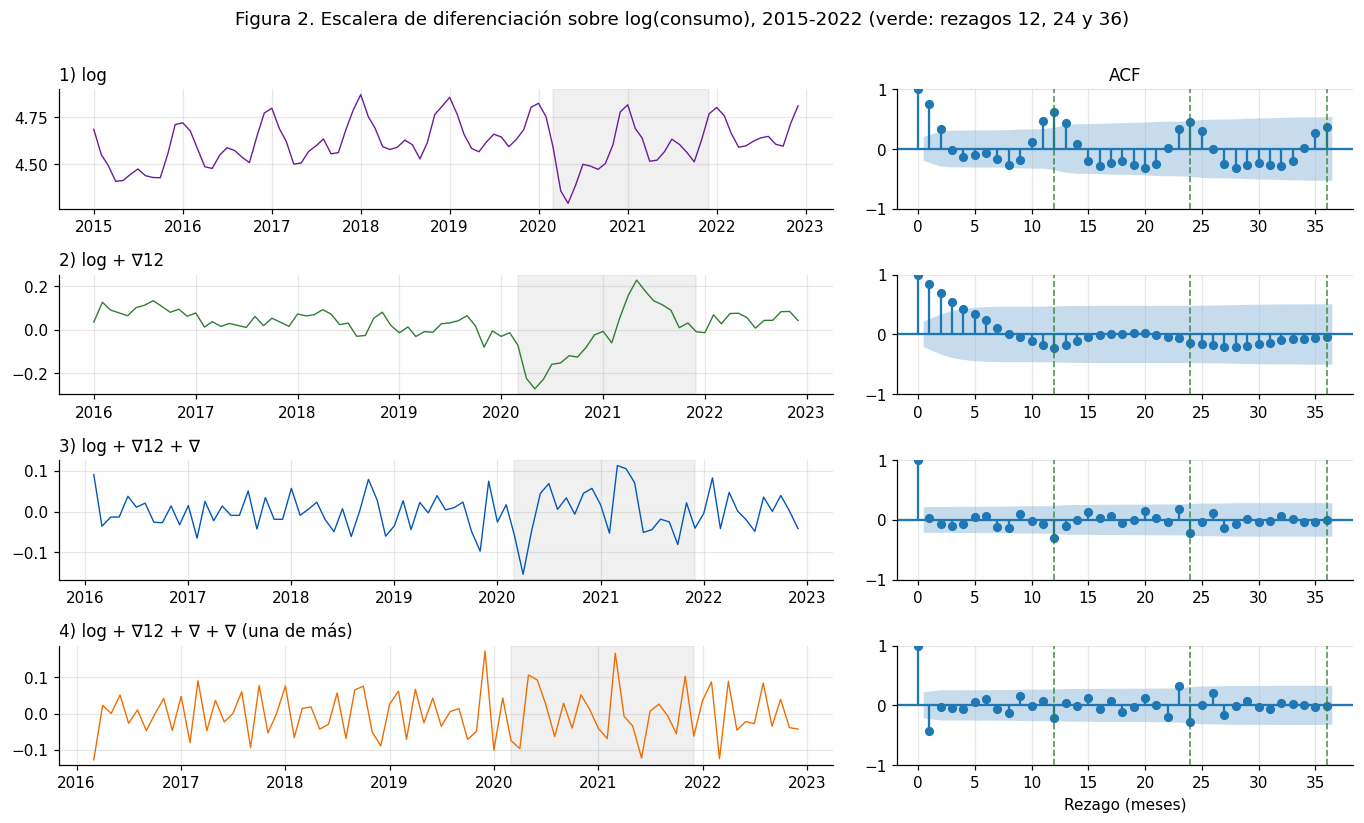

,n,p ADF,p KPSS,varianza,ρ1,ρ12,veredicto (5 %)
serie,,,,,,,
0) original (GWh),96,"0,2098","≥ 0,10","1,45e+02","+0,750","+0,665",ambiguo
1) log,96,"0,1552","≥ 0,10","1,40e-02","+0,758","+0,621",ambiguo
2) log + ∇12,84,"0,1009","≥ 0,10","7,12e-03","+0,849","-0,228",ambiguo
2b) log + ∇,95,"0,0800","≥ 0,10","6,37e-03","+0,470","+0,757",ambiguo
3) log + ∇12 + ∇,83,"0,0000","≥ 0,10","2,17e-03","+0,032","-0,298",estacionaria
4) log + ∇12 + ∇ + ∇ (una de más),82,"0,0000","≥ 0,10","4,12e-03","-0,425","-0,208",estacionaria


Evidencia
  · Box-Cox: λ̂ = 0,004 (IC 95 % [−1,45; 1,49]); pendiente log(desv.) ~ log(media), años sin covid = 0,25.
  · Residuos STL, años sin covid: Spearman(|residuo|, nivel) = 0,04 aditivo y 0,02 log; asimetría 1,15 → 0,67.
  · Log: ADF p = 0,155 (con tendencia: 0,391); KPSS p ≥ 0,10.
  · Solo ∇12: ADF p = 0,101, ρ1 = 0,849 | solo ∇: ADF p = 0,080, ρ12 = 0,757.
  · ∇∇12: ADF p < 0,001; KPSS p ≥ 0,10; varianza −70 %.
  · Una diferencia regular más: varianza +90 %; ρ1 = −0,425.


In [2]:
# Todo el análisis de esta sección usa solo y_train (2015-2022)
ly_train = np.log(y_train).rename("log_consumo")
covid = (df.index[df["covid"] == 1].min(), df.index[df["covid"] == 1].max())

# Figura 1: nivel, dispersión y patrón estacional del entrenamiento
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1.9, 1]})
ax = axes[0]
ax.axvspan(*covid, color=GRIS, alpha=0.2, label="covid = 1")
ax.plot(y_train.index, y_train, color=ROJO, lw=1.2, label="consumo mensual")
ax.plot(y_train.index, y_train.rolling(S).mean(), color="k", lw=1.8, label="media móvil (12)")
ax2 = ax.twinx()
ax2.plot(y_train.index, y_train.rolling(S).std(), color=AZUL, lw=1.5, ls="--", label="desv. estándar móvil (12)")
ax2.set_ylabel("Desv. estándar móvil (GWh)", color=AZUL); ax2.grid(False)
ax.set(ylabel="Consumo (GWh)", title="(a) Entrenamiento 2015-2022")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", ncol=2)
colores_anio = plt.cm.viridis(np.linspace(0, 0.95, y_train.index.year.nunique()))
for color, (anio, g) in zip(colores_anio, y_train.groupby(y_train.index.year)):
    axes[1].plot(g.index.month, g.values, color=color, lw=2.0 if anio == 2020 else 1.1,
                 ls="--" if anio in (2020, 2021) else "-", label=str(anio))
axes[1].set_xticks(range(1, 13), list("EFMAMJJASOND")); axes[1].set(xlabel="Mes", title="(b) Superposición anual por año")
axes[1].legend(ncol=2, title="año (-- covid)", title_fontsize=8)
fig.suptitle("Figura 1. Consumo eléctrico comercial, entrenamiento 2015-2022", y=1.02)
plt.tight_layout(); plt.show()

# Transformación: λ de Box-Cox, dispersión frente a nivel y residuos de STL aditivo frente a STL sobre log
lam, ic_lam = stats.boxcox(y_train.to_numpy(), alpha=ALFA)[1:]
sin_covid = ~y_train.index.year.isin([2020, 2021])
anual = y_train[sin_covid].groupby(lambda t: t.year).agg(["mean", "std"])
beta, _ = np.polyfit(np.log(anual["mean"]), np.log(anual["std"]), 1)
stl_res = {}
for nombre, serie in [("aditivo", y_train), ("log", ly_train)]:
    comp = STL(serie, period=S, robust=True).fit()
    nivel = np.exp(comp.trend) if nombre == "log" else comp.trend
    rho = stats.spearmanr(comp.resid.abs()[sin_covid], nivel[sin_covid])[0]   # ¿crece el residuo con el nivel?
    stl_res[nombre] = (rho, stats.skew(comp.resid[sin_covid]))

# Escalera de diferenciación: ADF (H0: raíz unitaria) y KPSS (H0: estacionariedad en nivel)
def diagnostico_estacionariedad(serie, nombre, alpha=ALFA):
    x = np.asarray(serie, dtype=float)
    p_adf = adfuller(x, autolag="AIC")[1]
    with warnings.catch_warnings():                          # KPSS avisa si su p cae fuera de la tabla;
        warnings.simplefilter("ignore", InterpolationWarning)  # se informa como "≥ 0,10" o "≤ 0,01"
        p_kpss = kpss(x, regression="c", nlags="auto")[1]
    veredicto = {(True, True): "estacionaria", (False, False): "no estacionaria"}.get((p_adf < alpha, p_kpss > alpha), "ambiguo")
    r = acf(x, nlags=S)
    return {"serie": nombre, "n": len(x), "p ADF": p_adf, "p KPSS": p_kpss, "varianza": float(np.var(x)),
            "ρ1": r[1], "ρ12": r[S], "veredicto (5 %)": veredicto}

escalera = [(y_train, "0) original (GWh)", ROJO), (ly_train, "1) log", MORADO),
            (ly_train.diff(S).dropna(), "2) log + ∇12", VERDE), (ly_train.diff(1).dropna(), "2b) log + ∇", GRIS),
            (ly_train.diff(S).diff(1).dropna(), "3) log + ∇12 + ∇", AZUL),
            (ly_train.diff(S).diff(1).diff(1).dropna(), "4) log + ∇12 + ∇ + ∇ (una de más)", NARANJA)]
graf = [e for e in escalera if e[1][:2] in ("1)", "2)", "3)", "4)")]
fig, axes = plt.subplots(len(graf), 2, figsize=(12.5, 7.4), gridspec_kw={"width_ratios": [1.7, 1]})
for fila, (serie, titulo, color) in enumerate(graf):
    axes[fila, 0].plot(serie.index, serie.to_numpy(), color=color, lw=0.9)
    axes[fila, 0].axvspan(*covid, color=GRIS, alpha=0.15); axes[fila, 0].set_title(titulo, loc="left")
    plot_acf(serie.to_numpy(), lags=36, ax=axes[fila, 1], title="ACF" if fila == 0 else "")
    for k in (12, 24, 36):
        axes[fila, 1].axvline(k, color=VERDE, ls="--", lw=1.1, alpha=0.8)
axes[-1, 1].set_xlabel("Rezago (meses)")
fig.suptitle("Figura 2. Escalera de diferenciación sobre log(consumo), 2015-2022 (verde: rezagos 12, 24 y 36)", y=1.005)
plt.tight_layout(); plt.show()

T = pd.DataFrame([diagnostico_estacionariedad(s_, t) for s_, t, _ in escalera]).set_index("serie")
p_kpss_txt = lambda p: "≥ 0,10" if p >= 0.1 else ("≤ 0,01" if p <= 0.01 else num(p, 3))
display(T.style.format({"p ADF": "{:.4f}", "p KPSS": p_kpss_txt, "varianza": "{:.2e}", "ρ1": "{:+.3f}", "ρ12": "{:+.3f}"}, decimal=",")
        .set_caption("Tabla 1. ADF (H0: raíz unitaria) y KPSS (H0: estacionariedad) por peldaño, entrenamiento 2015-2022"))

FINAL, UNA_MAS = "3) log + ∇12 + ∇", "4) log + ∇12 + ∇ + ∇ (una de más)"
p_adf_ct = adfuller(ly_train, regression="ct", autolag="AIC")[1]          # ADF con tendencia sobre log, como contraste
cambio_var = lambda a, b: 100 * (T.loc[b, "varianza"] / T.loc[a, "varianza"] - 1)
evidencia(
    f"Box-Cox: λ̂ = {num(lam, 3)} (IC 95 % [{num(ic_lam[0])}; {num(ic_lam[1])}]); pendiente log(desv.) ~ log(media), años sin covid = {num(beta)}.",
    f"Residuos STL, años sin covid: Spearman(|residuo|, nivel) = {num(stl_res['aditivo'][0])} aditivo y {num(stl_res['log'][0])} log; "
    f"asimetría {num(stl_res['aditivo'][1])} → {num(stl_res['log'][1])}.",
    f"Log: ADF p = {pval(T.loc['1) log', 'p ADF'])} (con tendencia: {pval(p_adf_ct)}); KPSS p {p_kpss_txt(T.loc['1) log', 'p KPSS'])}.",
    f"Solo ∇12: ADF p = {pval(T.loc['2) log + ∇12', 'p ADF'])}, ρ1 = {num(T.loc['2) log + ∇12', 'ρ1'], 3)} | "
    f"solo ∇: ADF p = {pval(T.loc['2b) log + ∇', 'p ADF'])}, ρ12 = {num(T.loc['2b) log + ∇', 'ρ12'], 3)}.",
    f"∇∇12: ADF p {pval(T.loc[FINAL, 'p ADF'])}; KPSS p {p_kpss_txt(T.loc[FINAL, 'p KPSS'])}; varianza {pct(cambio_var('2) log + ∇12', FINAL), 0)}.",
    f"Una diferencia regular más: varianza {pct(cambio_var(FINAL, UNA_MAS), 0)}; ρ1 = {num(T.loc[UNA_MAS, 'ρ1'], 3)}.")

**Interpretación.**
- *Transformación.* El λ̂ de Box-Cox es consistente con una transformación logarítmica (Box y Cox, 1964), aunque su intervalo también incluye λ = 1. Atendiendo la retroalimentación de la Sumativa 1, se compararon los residuos de STL aditivo y STL sobre log: en ninguno su magnitud crece con el nivel, y el logaritmo reduce su asimetría. La evidencia es moderada; se adopta el logaritmo porque λ̂ ≈ 0 y porque expresa errores y coeficientes en términos relativos.
- *Serie en log.* ADF (H0: raíz unitaria; Dickey y Fuller, 1979) no rechaza, con o sin tendencia, y KPSS (H0: estacionariedad; Kwiatkowski et al., 1992) tampoco. Las pruebas no concuerdan, pero la ACF decae lentamente: la serie no se trata como estacionaria.
- *Diferenciación.* Con una sola diferencia, ADF sigue sin rechazar al 5 % y queda autocorrelación alta en el rezago no diferenciado. Con ∇∇₁₂, ADF rechaza, KPSS no rechaza y la varianza cae. Otra diferencia regular sube la varianza y deja ρ1 negativo y grande: es sobrediferenciación, que ADF por sí solo no detecta (Rosas, 2026).

**Decisión.** Logaritmo, d = 1, D = 1 y s = 12: la combinación mínima que ambas pruebas califican de estacionaria, verificada en el peldaño 3 de la Tabla 1.

## 2. Identificación y estimación de modelos

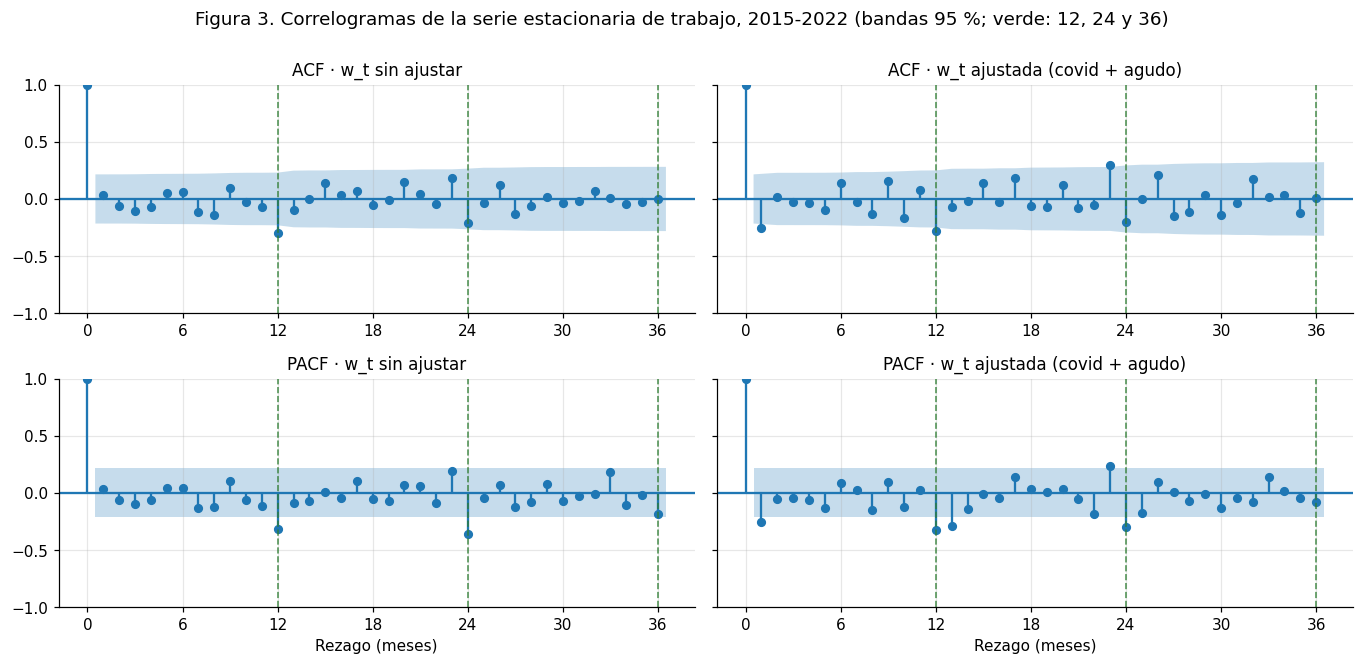

Evidencia
  · n = 83; banda 95 % = ±0,215; con 36 rezagos se esperan ≈ 1,8 cruces por azar.
  · w_t sin ajustar → ACF fuera de banda: 12 (−0,298) | PACF: 12 (−0,316), 24 (−0,358).
  · Si la estacionalidad fuera AR(1) con Φ ≈ ρ12, la ACF esperada en 24 sería Φ² ≈ 0,089, dentro de la banda.
  · El shock afecta 34 de 83 valores de w_t. w_t ajustada → ACF: 1 (−0,256), 12 (−0,281), 23 (0,293) | PACF: 1 (−0,256), 12 (−0,329), 13 (−0,293), 23 (0,236), 24 (−0,299).


In [3]:
# Indicadoras de intervención (análisis complementario): delimitadas con datos de entrenamiento y nulas en 2023
X = pd.DataFrame({"covid": df["covid"].astype(float),                                               # indicadora oficial del CSV
                  "agudo": ((df.index >= "2020-04-01") & (df.index <= "2020-06-01")).astype(float)},  # fase aguda, abril-junio 2020
                 index=df.index)
X_train, X_val = X.loc[y_train.index], X.loc[y_val.index]
assert (X_val == 0).all().all()

# Serie estacionaria de trabajo w_t = (1-B)(1-B^12) log y_t, sin ajustar y con el shock descontado (solo train)
w = ly_train.diff(S).diff(1).dropna().rename("w")
pre = SARIMAX(ly_train, exog=X_train, order=(0, 1, 0), seasonal_order=(0, 1, 0, S)).fit(disp=False)   # efecto preliminar
w_aj = (ly_train - X_train @ pre.params[["covid", "agudo"]]).diff(S).diff(1).dropna().rename("w_aj")
meses_covid = df.index[df["covid"] == 1]
afectadas = sum(any(t - pd.DateOffset(months=k) in meses_covid for k in (0, 1, 12, 13)) for t in w.index)

fig, axes = plt.subplots(2, 2, figsize=(12.5, 6.0), sharey=True)
for col, (serie, nombre) in enumerate([(w, "w_t sin ajustar"), (w_aj, "w_t ajustada (covid + agudo)")]):
    plot_acf(serie.to_numpy(), lags=36, ax=axes[0, col], title=f"ACF · {nombre}")
    plot_pacf(serie.to_numpy(), lags=36, ax=axes[1, col], method="ywm", title=f"PACF · {nombre}")
    for ax in axes[:, col]:
        for k in (12, 24, 36):
            ax.axvline(k, color=VERDE, ls="--", lw=1.1, alpha=0.8)
        ax.set_xticks(range(0, 37, 6))
axes[1, 0].set_xlabel("Rezago (meses)"); axes[1, 1].set_xlabel("Rezago (meses)")
fig.suptitle("Figura 3. Correlogramas de la serie estacionaria de trabajo, 2015-2022 (bandas 95 %; verde: 12, 24 y 36)", y=1.0)
plt.tight_layout(); plt.show()

banda = 1.96 / np.sqrt(len(w))
fuera = lambda r: ", ".join(f"{k} ({num(r[k], 3)})" for k in range(1, 37) if abs(r[k]) > banda)
r_w, rp_w = acf(w, nlags=36), pacf(w, nlags=36, method="ywm")
r_aj, rp_aj = acf(w_aj, nlags=36), pacf(w_aj, nlags=36, method="ywm")
evidencia(
    f"n = {len(w)}; banda 95 % = ±{num(banda, 3)}; con 36 rezagos se esperan ≈ {num(36 * ALFA, 1)} cruces por azar.",
    f"w_t sin ajustar → ACF fuera de banda: {fuera(r_w)} | PACF: {fuera(rp_w)}.",
    f"Si la estacionalidad fuera AR(1) con Φ ≈ ρ12, la ACF esperada en 24 sería Φ² ≈ {num(r_w[S] ** 2, 3)}, dentro de la banda.",
    f"El shock afecta {afectadas} de {len(w)} valores de w_t. w_t ajustada → ACF: {fuera(r_aj)} | PACF: {fuera(rp_aj)}.")

**Lectura por bloques (Fig. 3).** En el bloque estacional, la ACF de $w_t = \nabla\nabla_{12}\log y_t$ corta en 12 y la PACF es significativa en 12 y 24: patrón de MA(1) estacional. La ACF no descarta un AR(1) estacional, cuya autocorrelación en 24 quedaría dentro de la banda. En el bloque regular no hay señal; al descontar el shock de 2020 aparece el rezago 1. El rezago 23 es aislado y se esperan cerca de dos cruces por azar (Hyndman y Athanasopoulos, 2021).

**Candidatos, definidos antes de validar:** M1, MA(1) estacional; M2 y M3, M1 más MA(1) o AR(1) regular; M4, la lectura alternativa AR(1) estacional. Fuera de los candidatos, M6 es un análisis complementario de intervención: agrega a M2 las indicadoras `covid` y `agudo` (abril–junio de 2020) para representar una perturbación extraordinaria (Box y Tiao, 1975).

In [4]:
# Candidatos definidos ANTES de la validación: (orden, orden estacional, intervenciones, justificación desde la Fig. 3)
CANDIDATOS = {
    "M1": ((0, 1, 0), (0, 1, 1, S), None, "ACF de w_t solo en 12 → MA(1) estacional"),
    "M2": ((0, 1, 1), (0, 1, 1, S), None, "M1 + MA(1) regular por el rezago 1 de w_t ajustada"),
    "M3": ((1, 1, 0), (0, 1, 1, S), None, "M1 + AR(1) regular: contraste de M2"),
    "M4": ((0, 1, 0), (1, 1, 0, S), None, "Lectura alternativa: AR(1) estacional (PACF en 12)"),
    "M6": ((0, 1, 1), (0, 1, 1, S), ["covid", "agudo"], "Complementario: M2 + intervención (Box y Tiao)"),
}
SARIMA, PRINCIPALES, COMPLEMENTARIO = list(CANDIDATOS), ["M1", "M2", "M3", "M4"], "M6"
GRIEGA = {"ar.L1": "φ1", "ma.L1": "θ1", "ar.S.L12": "Φ1", "ma.S.L12": "Θ1", "covid": "covid", "agudo": "agudo"}

def estimar(serie, orden, orden_est, exog=None, maxiter=200):
    """Máxima verosimilitud (L-BFGS). Si no converge, reintenta con Powell desde el mismo punto antes de descartar el modelo.
    Devuelve el ajuste y el número de avisos de convergencia del ajuste final."""
    modelo = SARIMAX(serie, exog=exog, order=orden, seasonal_order=orden_est)
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        fit = modelo.fit(disp=False, maxiter=maxiter)
    n_avisos = sum(issubclass(a.category, ConvergenceWarning) for a in avisos)
    if n_avisos or not fit.mle_retvals.get("converged", True):
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always")
            fit = modelo.fit(start_params=fit.params, method="powell", maxiter=1000, disp=False)
        n_avisos = sum(issubclass(a.category, ConvergenceWarning) for a in avisos)
    return fit, n_avisos

def sin_parametro(orden, orden_est, param):
    """Órdenes del modelo restringido (param = 0) para la prueba de razón de verosimilitud (LR)."""
    (p, d, q), (P, D, Q, s) = orden, orden_est
    return {"ar.L1": ((0, d, q), orden_est), "ma.L1": ((p, d, 0), orden_est),
            "ar.S.L12": (orden, (0, D, Q, s)), "ma.S.L12": (orden, (P, D, 0, s))}[param]

ajustes, pv, filas = {}, {}, []
for nombre, (orden, orden_est, cols, motivo) in CANDIDATOS.items():
    Xe = None if cols is None else X_train[cols]
    fit, av = estimar(ly_train, orden, orden_est, Xe)
    assert fit.nobs == len(y_train) and fit.fittedvalues.index.max() == y_train.index.max(), "el ajuste no debe ver 2023"
    ajustes[nombre] = fit
    for p in fit.param_names[:-1]:                     # p-valor: LR para términos ARMA, Wald para intervenciones
        if p.startswith(("ar.", "ma.")):
            restr, _ = estimar(ly_train, *sin_parametro(orden, orden_est, p), Xe)
            pv[(nombre, p)] = stats.chi2.sf(max(2 * (fit.llf - restr.llf), 0), 1)
        else:
            pv[(nombre, p)] = fit.pvalues[p]
    ok = fit.mle_retvals.get("converged", True) and av == 0 and np.all(np.linalg.eigvalsh(-fit.model.hessian(fit.params)) > 0)
    filas.append({"modelo": nombre, "orden": f"{orden}{orden_est[:3]}12" + ("" if cols is None else " + " + " + ".join(cols)),
                  "justificación": motivo,
                  "coeficientes (p LR o Wald)": "; ".join(f"{GRIEGA[p]} = {num(fit.params[p], 3)} ({pval(pv[(nombre, p)])})"
                                                          for p in fit.param_names[:-1]),
                  "|raíz| mín": np.concatenate([np.abs(fit.arroots), np.abs(fit.maroots)]).min(),
                  "converge y Hessiano DP": "sí" if ok else "NO"})
tabla_est = pd.DataFrame(filas).set_index("modelo")
display(tabla_est.style.format({"|raíz| mín": "{:.3f}"}, decimal=",")
        .set_caption("Tabla 2. Candidatos y estimación por máxima verosimilitud, 2015-2022 (M6: análisis complementario de intervención)"))

# Diagnóstico previo de todos los candidatos y contraste ante Θ1 ≈ −1 (¿estacionalidad determinista?)
N_DESCARTAR = 1 + 1 * S                                      # d + D·s residuos iniciales, artificiales con d = D = 1
residuos = lambda fit: pd.Series(np.asarray(fit.resid), index=ly_train.index).iloc[N_DESCARTAR:]
def ljung_box(fit):
    m_arma = sum(p.startswith(("ar.", "ma.")) for p in fit.param_names)       # gl = K − (p + q + P + Q)
    return acorr_ljungbox(residuos(fit), lags=[12, 24], model_df=m_arma, return_df=True)["lb_pvalue"]
p_lb = {m: ljung_box(f) for m, f in ajustes.items()}
MESES = pd.get_dummies(df.index.month, prefix="mes", dtype=float).iloc[:, 1:].set_index(df.index)
m_det, _ = estimar(ly_train, (0, 1, 1), (0, 0, 0, 0), pd.concat([X_train, MESES.loc[y_train.index]], axis=1))
lb_det = acorr_ljungbox(pd.Series(np.asarray(m_det.resid), index=ly_train.index).iloc[1:], lags=[24], model_df=1)["lb_pvalue"]
cerca_frontera = [m for m, f in ajustes.items() if len(f.maroots) and np.abs(f.maroots).min() < 1.01]
evidencia(
    f"Converge y Hessiano definido positivo: {'todos' if tabla_est['converge y Hessiano DP'].eq('sí').all() else 'revisar Tabla 2'}. "
    f"MA estacional a menos de 0,01 del límite de invertibilidad: {', '.join(cerca_frontera)}.",
    "Ljung-Box p (K = 12 / K = 24): " + "; ".join(f"{m} {num(v[12], 3)} / {num(v[24], 3)}" for m, v in p_lb.items()) + ".",
    f"Contraste D = 0 (ARIMA(0,1,1) + indicadoras mensuales + intervención): Ljung-Box K = 24, p = {pval(lb_det[24])}.")

,orden,justificación,coeficientes (p LR o Wald),|raíz| mín,converge y Hessiano DP
modelo,,,,,
M1,"(0, 1, 0)(0, 1, 1)12",ACF de w_t solo en 12 → MA(1) estacional,"Θ1 = −0,982 (< 0,001)","1,001",sí
M2,"(0, 1, 1)(0, 1, 1)12",M1 + MA(1) regular por el rezago 1 de w_t ajustada,"θ1 = −0,051 (0,689); Θ1 = −0,971 (< 0,001)","1,002",sí
M3,"(1, 1, 0)(0, 1, 1)12",M1 + AR(1) regular: contraste de M2,"φ1 = −0,044 (0,696); Θ1 = −0,979 (< 0,001)","1,002",sí
M4,"(0, 1, 0)(1, 1, 0)12",Lectura alternativa: AR(1) estacional (PACF en 12),"Φ1 = −0,311 (0,004)","1,102",sí
M6,"(0, 1, 1)(0, 1, 1)12 + covid + agudo",Complementario: M2 + intervención (Box y Tiao),"covid = −0,058 (< 0,001); agudo = −0,129 (< 0,001); θ1 = −0,462 (< 0,001); Θ1 = −0,969 (< 0,001)","1,003",sí


Evidencia
  · Converge y Hessiano definido positivo: todos. MA estacional a menos de 0,01 del límite de invertibilidad: M1, M2, M3, M6.
  · Ljung-Box p (K = 12 / K = 24): M1 0,607 / 0,175; M2 0,594 / 0,212; M3 0,583 / 0,202; M4 0,679 / 0,059; M6 0,340 / 0,040.
  · Contraste D = 0 (ARIMA(0,1,1) + indicadoras mensuales + intervención): Ljung-Box K = 24, p = 0,001.


**Interpretación.** Todos convergen con Hessiano definido positivo. Los términos regulares no son significativos en M2 ni M3 y solo lo son junto a la intervención (M6). Los MA estacionales quedan próximos al límite de invertibilidad, por lo que sus coeficientes se leen con cautela; M4 no tiene ese problema. Con D = 0 e indicadoras mensuales persiste autocorrelación, así que se mantiene D = 1. Ningún candidato rechaza Ljung-Box en K = 12, y todos pasan a validación.

## 3. Selección y comparación de modelos

,AIC,BIC,RMSE,MAE,ME,mejora RMSE vs naive (%),rol
M1,"-300,0","-295,2","7,20","6,71","+6,71","+0,8",Descartado
M2,"-298,2","-291,0","7,07","6,56","+6,56","+2,7",Descartado
M3,"-298,2","-290,9","7,09","6,58","+6,58","+2,4",Descartado
M4,"-277,8","-273,0","4,12","3,71","+3,21","+43,2",Principal de pronóstico
M6,"-331,4","-319,3","5,71","5,20","+5,20","+21,4",Complementario (intervención)
Naive estacional,—,—,"7,26","6,53","+6,53","+0,0",Referencia
Naive con deriva,—,—,"4,72","4,22","+3,55","+35,0",Referencia


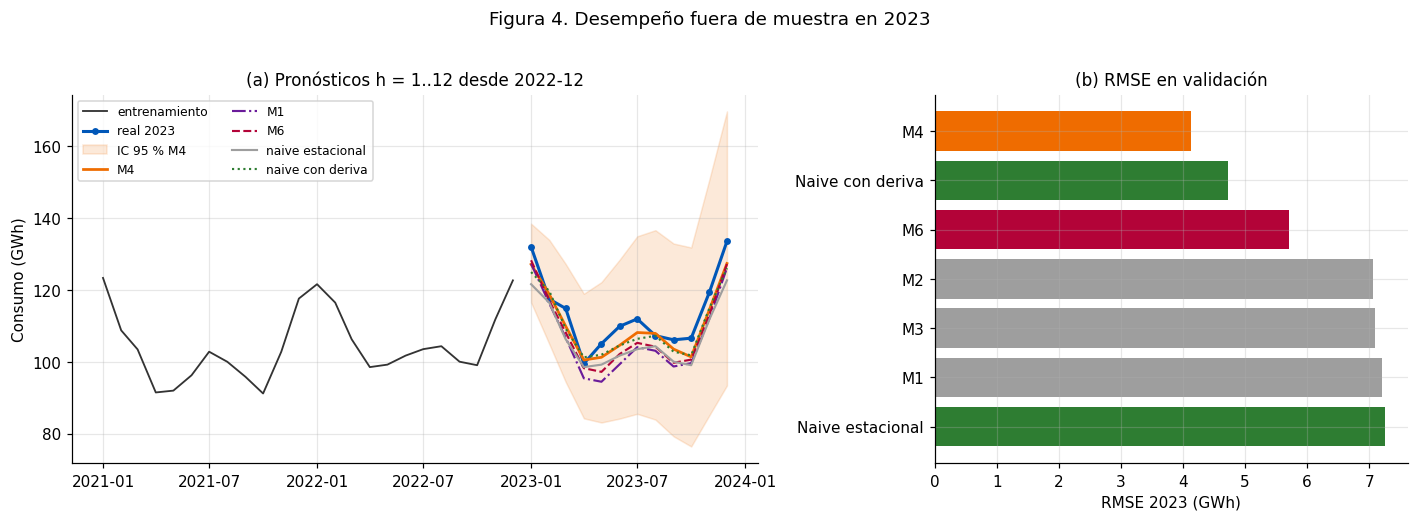

Evidencia
  · Menor RMSE y MAE: M4 (4,12 y 3,71 GWh); RMSE 43,2 % menor que el naive estacional y 12,6 % menor que el naive con deriva.
  · Menor AIC/BIC entre M1-M4: M1 (−300,0 / −295,2); con intervención, M6: −331,4 / −319,3.
  · Crecimiento medio 2023 / 2022: real +6,1 % | M1 −0,2 % | M2 0,0 % | M3 0,0 % | M4 +3,1 % | M6 +1,2 % | Naive estacional 0,0 % | Naive con deriva +2,8 %.
  · Meses de 2023 subestimados (de 12): M1 12, M2 12, M3 12, M4 9, M6 12, Naive estacional 12, Naive con deriva 10. Cobertura IC 95 %: M1 100 %, M2 100 %, M3 100 %, M4 100 %, M6 100 %.
  · M6: desviación del nivel −5,6 % en meses covid = 1 y −17,1 % en abril-junio de 2020.


In [7]:
# Validación: se pronostican 12 meses desde 2022-12 sin reestimar ni usar observaciones reales de 2023
rmse = lambda e: float(np.sqrt(np.mean(np.square(e))))
mae  = lambda e: float(np.mean(np.abs(e)))
real = y_val.to_numpy()

def pronosticar(fit, exog_futuro=None):
    """Pronóstico h = 1..12 en GWh: media con corrección de sesgo exp(m + v/2) e IC 95 % retransformado."""
    f = fit.get_forecast(steps=len(y_val), exog=exog_futuro)
    assert f.predicted_mean.index.equals(y_val.index), "los pronósticos deben corresponder a 2023"
    m, v = np.asarray(f.predicted_mean), np.asarray(f.var_pred_mean)
    ic = np.exp(np.asarray(f.conf_int(alpha=ALFA)))
    return {"media": np.exp(m + v / 2), "inferior": ic[:, 0], "superior": ic[:, 1]}

# Referencia obligatoria: naive estacional (repite 2022); referencia adicional: naive estacional con deriva
naive_val = y_train["2022"].to_numpy()
g_medio = np.mean(y_train.to_numpy()[S:] / y_train.to_numpy()[:-S] - 1)          # crecimiento interanual medio 2016-2022
naive_deriva = naive_val * (1 + g_medio)
BENCH = ["Naive estacional", "Naive con deriva"]

pronos = {m: pronosticar(f, None if CANDIDATOS[m][2] is None else X_val[CANDIDATOS[m][2]]) for m, f in ajustes.items()}
preds = {**{m: pronos[m]["media"] for m in SARIMA}, BENCH[0]: naive_val, BENCH[1]: naive_deriva}
tabla_comp = pd.DataFrame({m: {"AIC": ajustes[m].aic if m in ajustes else np.nan, "BIC": ajustes[m].bic if m in ajustes else np.nan,
                               "RMSE": rmse(real - p), "MAE": mae(real - p), "ME": float(np.mean(real - p))}
                           for m, p in preds.items()}).T

# Regla fijada antes de ver los errores: menor RMSE en 2023, con MAE como respaldo
SELECCIONADO = tabla_comp.loc[SARIMA, "RMSE"].idxmin()
mejora = lambda m, b, c="RMSE": 100 * (1 - tabla_comp.loc[m, c] / tabla_comp.loc[b, c])
tabla_comp["mejora RMSE vs naive (%)"] = [mejora(m, BENCH[0]) for m in tabla_comp.index]
tabla_comp["rol"] = ["Principal de pronóstico" if m == SELECCIONADO else "Complementario (intervención)" if m == COMPLEMENTARIO
                     else "Referencia" if m in BENCH else "Descartado" for m in tabla_comp.index]
display(tabla_comp.style.format({"AIC": "{:.1f}", "BIC": "{:.1f}", "RMSE": "{:.2f}", "MAE": "{:.2f}", "ME": "{:+.2f}",
                                 "mejora RMSE vs naive (%)": "{:+.1f}"}, decimal=",", na_rep="—")
        .set_caption("Tabla 3. AIC/BIC dentro de muestra (2015-2022) y error fuera de muestra en 2023, en GWh (ME > 0: subestima)"))

# Figura 4
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.45, 1]})
ax = axes[0]
ax.plot(y_train["2021-01":].index, y_train["2021-01":], color="#333333", lw=1.2, label="entrenamiento")
ax.plot(y_val.index, real, color=AZUL, lw=2, marker="o", ms=3.5, label="real 2023")
ax.fill_between(y_val.index, pronos[SELECCIONADO]["inferior"], pronos[SELECCIONADO]["superior"], color=NARANJA, alpha=0.15,
                label=f"IC 95 % {SELECCIONADO}")
for nombre, pred, color, ls in [(SELECCIONADO, preds[SELECCIONADO], NARANJA, "-"), ("M1", preds["M1"], MORADO, "-."),
                                (COMPLEMENTARIO, preds[COMPLEMENTARIO], ROJO, "--"), ("naive estacional", naive_val, GRIS, "-"),
                                ("naive con deriva", naive_deriva, VERDE, ":")]:
    ax.plot(y_val.index, pred, color=color, ls=ls, lw=1.8 if nombre == SELECCIONADO else 1.4, label=nombre)
ax.set(ylabel="Consumo (GWh)", title="(a) Pronósticos h = 1..12 desde 2022-12"); ax.legend(ncol=2, loc="upper left")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7))); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
orden_b = tabla_comp["RMSE"].sort_values()
axes[1].barh(range(len(orden_b)), orden_b, color=[NARANJA if m == SELECCIONADO else ROJO if m == COMPLEMENTARIO
                                                   else (VERDE if m in BENCH else GRIS) for m in orden_b.index])
axes[1].set_yticks(range(len(orden_b)), list(orden_b.index)); axes[1].invert_yaxis()
axes[1].set(xlabel="RMSE 2023 (GWh)", title="(b) RMSE en validación")
fig.suptitle("Figura 4. Desempeño fuera de muestra en 2023", y=1.02)
plt.tight_layout(); plt.show()

media_22 = y_train["2022"].mean()
crec = {k: round(100 * (v.mean() / media_22 - 1), 1) + 0.0 for k, v in {"real": real, **preds}.items()}
subest = {m: int((real > preds[m]).sum()) for m in preds}
cob = {m: np.mean((real >= pronos[m]["inferior"]) & (real <= pronos[m]["superior"])) for m in SARIMA}
desvio = np.exp(ajustes[COMPLEMENTARIO].params[["covid", "agudo"]].cumsum()) - 1
MEJOR_AIC_P = tabla_comp.loc[PRINCIPALES, "AIC"].idxmin()
evidencia(
    f"Menor RMSE y MAE: {SELECCIONADO} ({num(tabla_comp.loc[SELECCIONADO, 'RMSE'])} y {num(tabla_comp.loc[SELECCIONADO, 'MAE'])} GWh); "
    f"RMSE {num(mejora(SELECCIONADO, BENCH[0]), 1)} % menor que el naive estacional y {num(mejora(SELECCIONADO, BENCH[1]), 1)} % menor que el naive con deriva.",
    f"Menor AIC/BIC entre M1-M4: {MEJOR_AIC_P} ({num(tabla_comp.loc[MEJOR_AIC_P, 'AIC'], 1)} / {num(tabla_comp.loc[MEJOR_AIC_P, 'BIC'], 1)}); "
    f"con intervención, {COMPLEMENTARIO}: {num(tabla_comp.loc[COMPLEMENTARIO, 'AIC'], 1)} / {num(tabla_comp.loc[COMPLEMENTARIO, 'BIC'], 1)}.",
    "Crecimiento medio 2023 / 2022: real " + pct(crec["real"]) + " | " + " | ".join(f"{m} {pct(crec[m])}" for m in preds) + ".",
    "Meses de 2023 subestimados (de 12): " + ", ".join(f"{m} {subest[m]}" for m in preds) + ". "
    f"Cobertura IC 95 %: {', '.join(f'{m} {num(100 * c, 0)} %' for m, c in cob.items())}.",
    f"{COMPLEMENTARIO}: desviación del nivel {pct(100 * desvio['covid'])} en meses covid = 1 y {pct(100 * desvio['agudo'])} en abril-junio de 2020.")

**Validación.** Los modelos se estiman con 2015–2022 y generan 12 pronósticos desde diciembre de 2022, sin reestimar ni usar datos reales de 2023 (el código lo verifica). La media se retransforma con $\exp(\hat\mu_h + \hat\sigma_h^2/2)$ y RMSE y MAE se calculan en GWh (Hyndman y Athanasopoulos, 2021). Regla, fijada antes de ver los errores: menor RMSE, con MAE como respaldo.

**Interpretación.**
- AIC y BIC miden ajuste penalizado dentro de muestra y son comparables porque los modelos comparten log, d y D (Burnham y Anderson, 2004). RMSE y MAE miden error fuera de muestra. Aquí no coinciden: M1 tiene el menor AIC/BIC de los candidatos y M4 el menor error. Como el objetivo es pronosticar, prima la validación.
- M4 supera al naive estacional y al naive con deriva; M1–M3 apenas mejoran al naive estacional.
- Todos los modelos proyectan menos crecimiento que el observado en 2023 (+6,1 %). Una parte importante del error se asocia a ese aumento de nivel no capturado.
- *Análisis complementario (M6).* Logra el menor AIC al describir el nivel cerca de 6 % menor en meses `covid` y 17 % menor en abril–junio de 2020, desviaciones asociadas temporalmente al período COVID y sin interpretación causal. No mejora el pronóstico: subestima los 12 meses de 2023 y no supera al naive con deriva.

**Decisión.** M4 = SARIMA(0,1,0)(1,1,0)₁₂ es el modelo de pronóstico: el menor error con un solo parámetro.

## 4. Diagnóstico de residuos y validación de supuestos

,H0,p M4,decisión M4 (5 %),p M6 (contraste)
Ljung-Box K = 12,sin autocorrelación conjunta hasta el rezago 12,"0,679",no rechaza H0,"0,340"
Ljung-Box K = 24,sin autocorrelación conjunta hasta el rezago 24,"0,059",no rechaza H0,"0,040"
Jarque-Bera,normalidad de los residuos,"0,564",no rechaza H0,"0,227"
ARCH-LM (12 rezagos),sin efectos ARCH (homocedasticidad condicional),"0,786",no rechaza H0,"0,825"
Goldfeld-Quandt (complementaria),igual varianza en la 1.ª y la 2.ª mitad,"0,017",rechaza H0,"0,659"


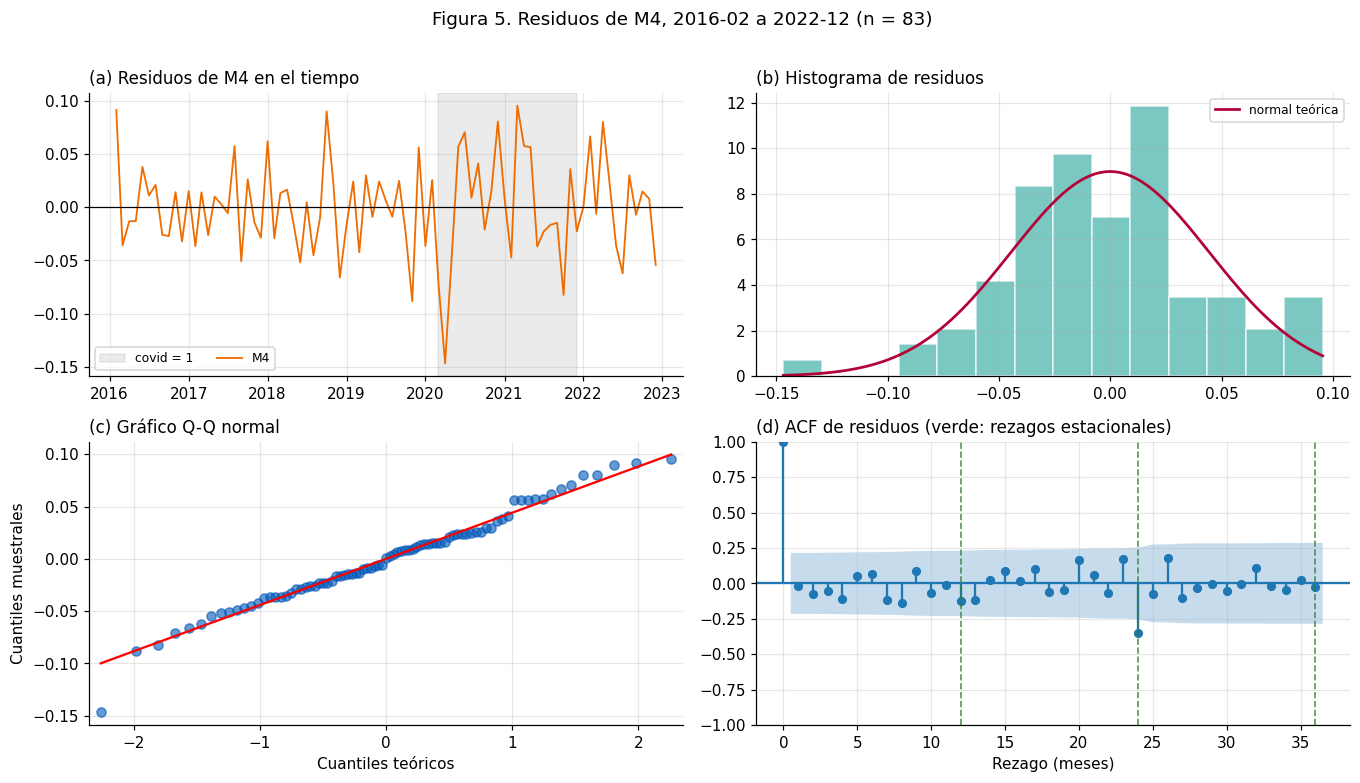

Evidencia
  · ACF residual de M4 fuera de ±0,215: rezago 24 (−0,35).
  · Mayor residuo absoluto: 2020-04 (0,147 en log). Goldfeld-Quandt: varianza de la 2.ª mitad (desde 2019-07) = 2,2 veces la de la 1.ª.
Control de coherencia: todas las verificaciones (14) y cifras del texto (25) coinciden con esta ejecución.


In [6]:
# Diagnóstico del modelo seleccionado (M4); M6 como contraste. Residuos en log, sin los 13 iniciales
PRUEBAS = {"Ljung-Box K = 12": "sin autocorrelación conjunta hasta el rezago 12",
           "Ljung-Box K = 24": "sin autocorrelación conjunta hasta el rezago 24",
           "Jarque-Bera": "normalidad de los residuos",
           "ARCH-LM (12 rezagos)": "sin efectos ARCH (homocedasticidad condicional)",
           "Goldfeld-Quandt (complementaria)": "igual varianza en la 1.ª y la 2.ª mitad"}
def bateria(fit):
    r, lb = residuos(fit), ljung_box(fit)
    gq = het_goldfeldquandt(r.to_numpy(), np.ones((len(r), 1)), split=0.5, drop=0.1, alternative="two-sided")
    return dict(zip(PRUEBAS, [lb[12], lb[24], stats.jarque_bera(r).pvalue, het_arch(r.to_numpy(), nlags=12)[1], gq[1]])), gq[0]

sel = ajustes[SELECCIONADO]
res = residuos(sel)
P, F_gq = bateria(sel)
P6, _ = bateria(ajustes[COMPLEMENTARIO])
tabla_diag = pd.DataFrame({"H0": PRUEBAS, f"p {SELECCIONADO}": P,
                           f"decisión {SELECCIONADO} (5 %)": {k: "rechaza H0" if v < ALFA else "no rechaza H0" for k, v in P.items()},
                           f"p {COMPLEMENTARIO} (contraste)": P6})
display(tabla_diag.style.format({f"p {SELECCIONADO}": "{:.3f}", f"p {COMPLEMENTARIO} (contraste)": "{:.3f}"}, decimal=",")
        .set_caption(f"Tabla 4. Diagnóstico de residuos de {SELECCIONADO}, 2015-2022 (n = {len(res)}; Ljung-Box con gl = K − parámetros ARMA)"))

fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.0))
axes[0, 0].axvspan(*covid, color=GRIS, alpha=0.2, label="covid = 1")
axes[0, 0].plot(res.index, res, color=NARANJA, lw=1.2, label=SELECCIONADO); axes[0, 0].axhline(0, color="k", lw=0.8)
axes[0, 0].set_title(f"(a) Residuos de {SELECCIONADO} en el tiempo", loc="left"); axes[0, 0].legend(ncol=2)
axes[0, 1].hist(res, bins=14, density=True, color="#4db6ac", alpha=0.75, edgecolor="white")
xx = np.linspace(res.min(), res.max(), 200)
axes[0, 1].plot(xx, stats.norm.pdf(xx, res.mean(), res.std()), color=ROJO, lw=1.8, label="normal teórica")
axes[0, 1].set_title("(b) Histograma de residuos", loc="left"); axes[0, 1].legend()
sm.qqplot(res.to_numpy(), line="s", ax=axes[1, 0], markerfacecolor=AZUL, markeredgecolor=AZUL, alpha=0.6)
axes[1, 0].set_title("(c) Gráfico Q-Q normal", loc="left"); axes[1, 0].set(xlabel="Cuantiles teóricos", ylabel="Cuantiles muestrales")
plot_acf(res.to_numpy(), lags=36, ax=axes[1, 1], title="")
for k in (12, 24, 36):
    axes[1, 1].axvline(k, color=VERDE, ls="--", lw=1.1, alpha=0.8)
axes[1, 1].set_title("(d) ACF de residuos (verde: rezagos estacionales)", loc="left"); axes[1, 1].set_xlabel("Rezago (meses)")
fig.suptitle(f"Figura 5. Residuos de {SELECCIONADO}, {res.index.min():%Y-%m} a {res.index.max():%Y-%m} (n = {len(res)})", y=1.01)
plt.tight_layout(); plt.show()

ra, banda_r = acf(res, nlags=36), 1.96 / np.sqrt(len(res))
mayor = res.abs().idxmax()
evidencia(
    f"ACF residual de {SELECCIONADO} fuera de ±{num(banda_r, 3)}: " + ", ".join(f"rezago {k} ({num(ra[k])})" for k in range(1, 37) if abs(ra[k]) > banda_r) + ".",
    f"Mayor residuo absoluto: {mayor:%Y-%m} ({num(res.abs().max(), 3)} en log). Goldfeld-Quandt: varianza de la 2.ª mitad "
    f"(desde {res.index[len(res) // 2]:%Y-%m}) = {num(F_gq, 1)} veces la de la 1.ª.")

# Control de coherencia (silencioso): partición sin leakage, jerarquía M4/M6 y cifras escritas en el texto
controles = {
    "ajustes sin datos posteriores a 2022-12": all(f.nobs == 96 and f.fittedvalues.index.max() == pd.Timestamp("2022-12-01") for f in ajustes.values()),
    "naive desde 2022 e intervenciones nulas en 2023": np.array_equal(naive_val, y_train["2022"].to_numpy()) and bool((X_val == 0).all().all()),
    "M4 menor RMSE y MAE; M1 menor AIC entre M1-M4": SELECCIONADO == "M4" == tabla_comp.loc[SARIMA, "MAE"].idxmin() and MEJOR_AIC_P == "M1",
    "M6 menor AIC y BIC global": tabla_comp.loc[SARIMA, "AIC"].idxmin() == tabla_comp.loc[SARIMA, "BIC"].idxmin() == COMPLEMENTARIO,
    "M4 supera ambos naive; M6 solo al estacional": all(mejora("M4", b, c) > 0 for b in BENCH for c in ("RMSE", "MAE")) and mejora("M6", BENCH[0]) > 0 > mejora("M6", BENCH[1]),
    "M1-M3 cerca del naive estacional": all(tabla_comp.loc[m, "RMSE"] > 0.95 * tabla_comp.loc[BENCH[0], "RMSE"] for m in ("M1", "M2", "M3")),
    "crecimiento 2023, subestimación y cobertura": all(crec[m] < crec["real"] for m in SARIMA) and subest["M6"] == 12 and subest["M4"] < 12 and min(cob.values()) == 1,
    "términos regulares": all(pv[(m, p)] > 0.6 for m, p in (("M2", "ma.L1"), ("M3", "ar.L1"))) and pv[("M6", "ma.L1")] < ALFA,
    "convergencia, frontera de invertibilidad y contraste D = 0": tabla_est["converge y Hessiano DP"].eq("sí").all() and set(cerca_frontera) == {"M1", "M2", "M3", "M6"} and lb_det[24] < ALFA,
    "Ljung-Box previo de los candidatos": all(p_lb[m][12] > ALFA for m in SARIMA) and [m for m in SARIMA if p_lb[m][24] < ALFA] == ["M6"],
    "diagnóstico de M4": ALFA < P["Ljung-Box K = 24"] < 0.10 and min(P["Jarque-Bera"], P["ARCH-LM (12 rezagos)"]) > ALFA > P["Goldfeld-Quandt (complementaria)"],
    "mayor residuo y rezago 24": mayor == pd.Timestamp("2020-04-01") and abs(ra[24]) > banda_r,
    "ADF y KPSS de la escalera": T.loc["1) log", "p ADF"] > ALFA and p_adf_ct > ALFA and T.loc[FINAL, "p ADF"] < 0.001 and T.loc[FINAL, "p KPSS"] >= 0.1,
    "residuos STL aditivo frente a log": abs(stl_res["aditivo"][0]) < 0.2 and abs(stl_res["log"][0]) < 0.2 and stl_res["log"][1] < stl_res["aditivo"][1],
}
# Cifras escritas a mano en el texto. Las que no pasan por el optimizador se exigen con el redondeo exacto;
# las que dependen de la máxima verosimilitud admiten ±1 en el último dígito, porque el punto en que el optimizador
# se detiene varía levemente entre versiones de SciPy/statsmodels (verificado con dos entornos distintos).
CITADAS = [("0,004", lam, 3), ("0,155", T.loc["1) log", "p ADF"], 3), ("0,101", T.loc["2) log + ∇12", "p ADF"], 3),
           ("90", cambio_var(FINAL, UNA_MAS), 0), ("−0,425", T.loc[UNA_MAS, "ρ1"], 3), ("−0,298", r_w[S], 3),
           ("−0,256", r_aj[1], 3), ("7,26", tabla_comp.loc[BENCH[0], "RMSE"], 2), ("6,1", crec["real"], 1)]
CITADAS_MV = [("−0,311", ajustes["M4"].params["ar.S.L12"], 3), ("0,0019", ajustes["M4"].params["sigma2"], 4),
              ("4,12", tabla_comp.loc["M4", "RMSE"], 2), ("3,71", tabla_comp.loc["M4", "MAE"], 2),
              ("43", mejora("M4", BENCH[0]), 0), ("13", mejora("M4", BENCH[1]), 0), ("−300,0", tabla_comp.loc["M1", "AIC"], 1),
              ("−295,2", tabla_comp.loc["M1", "BIC"], 1), ("7,2", tabla_comp.loc["M1", "RMSE"], 1), ("5,7", tabla_comp.loc["M6", "RMSE"], 1),
              ("0,679", P["Ljung-Box K = 12"], 3), ("0,059", P["Ljung-Box K = 24"], 3), ("0,564", P["Jarque-Bera"], 3),
              ("0,786", P["ARCH-LM (12 rezagos)"], 3), ("6", -100 * desvio["covid"], 0), ("17", -100 * desvio["agudo"], 0)]
def coincide(texto, valor, d, pasos):
    """Compara números (no cadenas): la cifra escrita debe estar a menos de `pasos` unidades de su último dígito."""
    escrito = float(texto.replace("−", "-").replace(",", "."))
    return bool(np.isclose(float(valor), escrito, rtol=0, atol=pasos * 10 ** -d))
fallas = ([f"el texto dice {t} y el cálculo da {num(v, d)}" for t, v, d in CITADAS if not coincide(t, v, d, 0.55)]
          + [f"el texto dice {t} y el cálculo da {num(v, d)}" for t, v, d in CITADAS_MV if not coincide(t, v, d, 1.5)])
fallidos = [nombre for nombre, ok in controles.items() if not ok]
assert not fallidos and not fallas, f"Inconsistencia texto-resultados. Controles fallidos: {fallidos}. Cifras: {fallas}"
print(f"Control de coherencia: todas las verificaciones ({len(controles)}) y cifras del texto ({len(CITADAS) + len(CITADAS_MV)}) coinciden con esta ejecución.")

**Interpretación (M4; 83 residuos tras descartar los 13 iniciales).**
- *Autocorrelación.* Ljung-Box (Ljung y Box, 1978), con grados de libertad descontando el parámetro ARMA, no rechaza en K = 12. En K = 24 no se rechaza la ausencia de autocorrelación residual al 5 %, aunque el resultado está próximo al umbral y debe interpretarse con cautela: la ACF residual muestra el rezago 24 fuera de banda.
- *Normalidad.* Jarque-Bera (Jarque y Bera, 1987) no rechaza; el mayor desvío del Q-Q es abril de 2020.
- *Homocedasticidad.* ARCH-LM (Engle, 1982), que evalúa heterocedasticidad condicional, no rechaza: no se detectan efectos ARCH significativos. Sin embargo, la prueba complementaria de Goldfeld-Quandt (Goldfeld y Quandt, 1965) evidencia diferencias de dispersión entre períodos: la segunda mitad, que contiene el período COVID, es más dispersa.
- *Contraste (M6).* A 24 rezagos rechaza Ljung-Box: conserva dependencia residual remanente.

**Validez del modelo.** M4 es utilizable para pronosticar, con reservas. La dependencia cercana al umbral en el rezago 24 sugiere estructura estacional no capturada del todo, y la diferencia de dispersión entre períodos afecta sobre todo a los intervalos, que deben tomarse como aproximados.

## Conclusiones

1. La serie en log no era estacionaria. Se estacionarizó con d = 1 y D = 1 (s = 12), la combinación mínima que ADF y KPSS aceptan sin sobrediferenciar.
2. Desde la ACF/PACF se estimaron cuatro candidatos (M1–M4), con M4 como lectura alternativa AR(1) estacional, y M6 como análisis complementario de intervención.
3. **M4 = SARIMA(0,1,0)(1,1,0)₁₂ se selecciona como modelo de pronóstico** por su mejor desempeño fuera de muestra (RMSE = 4,12 y MAE = 3,71 GWh en 2023) y su estructura parsimoniosa. Estimado con 2015–2022:
$$(1 + 0{,}311\,B^{12})(1-B)(1-B^{12})\log y_t = \varepsilon_t, \qquad \varepsilon_t \sim \mathrm{WN}(0,\ \hat\sigma^2 \approx 0{,}0019),$$
donde WN denota un proceso de ruido blanco con media cero y varianza constante.
4. M1 y M6 tienen mejor ajuste penalizado dentro de muestra, pero pronostican peor: un menor AIC/BIC no garantiza mejor capacidad predictiva. M6 representa la perturbación asociada temporalmente al período COVID y se conserva solo como análisis complementario.
5. El diagnóstico respalda a M4 con reservas: Ljung-Box en K = 24 está próximo al umbral y, aunque no se detectan efectos ARCH, Goldfeld-Quandt evidencia diferencias de dispersión entre períodos.

**Limitaciones y trabajo futuro.** La conclusión se restringe al único origen de validación disponible (2023), que además se usó para elegir, y debería contrastarse mediante validación temporal de origen móvil. Ningún modelo capturó el aumento de nivel de 2023; incorporar variables exógenas (clientes, temperatura, días hábiles) y reestimar el modelo cada diciembre son los pasos siguientes.

## Referencias (APA)

Box, G. E. P., y Cox, D. R. (1964). An analysis of transformations. *Journal of the Royal Statistical Society: Series B (Methodological)*, *26*(2), 211–252. https://doi.org/10.1111/j.2517-6161.1964.tb00553.x

Box, G. E. P., y Tiao, G. C. (1975). Intervention analysis with applications to economic and environmental problems. *Journal of the American Statistical Association*, *70*(349), 70–79. https://doi.org/10.1080/01621459.1975.10480264

Burnham, K. P., y Anderson, D. R. (2004). Multimodel inference: Understanding AIC and BIC in model selection. *Sociological Methods & Research*, *33*(2), 261–304. https://doi.org/10.1177/0049124104268644

Dickey, D. A., y Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root. *Journal of the American Statistical Association*, *74*(366a), 427–431. https://doi.org/10.1080/01621459.1979.10482531

Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica*, *50*(4), 987–1007. https://doi.org/10.2307/1912773

Goldfeld, S. M., y Quandt, R. E. (1965). Some tests for homoscedasticity. *Journal of the American Statistical Association*, *60*(310), 539–547. https://doi.org/10.1080/01621459.1965.10480811

Hyndman, R. J., y Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/

Jarque, C. M., y Bera, A. K. (1987). A test for normality of observations and regression residuals. *International Statistical Review*, *55*(2), 163–172. https://doi.org/10.2307/1403192

Kwiatkowski, D., Phillips, P. C. B., Schmidt, P., y Shin, Y. (1992). Testing the null hypothesis of stationarity against the alternative of a unit root. *Journal of Econometrics*, *54*(1–3), 159–178. https://doi.org/10.1016/0304-4076(92)90104-Y

Ljung, G. M., y Box, G. E. P. (1978). On a measure of lack of fit in time series models. *Biometrika*, *65*(2), 297–303. https://doi.org/10.1093/biomet/65.2.297

Rosas, H. (2026). *Del diagnóstico al pronóstico. Así se construye y se valida un SARIMA* [Cápsula docente]. Universidad Andrés Bello.

Seabold, S., y Perktold, J. (2010). Statsmodels: Econometric and statistical modeling with Python. En S. van der Walt y J. Millman (Eds.), *Proceedings of the 9th Python in Science Conference* (pp. 92–96). https://doi.org/10.25080/Majora-92bf1922-011

Universidad Andrés Bello. (s. f.-a). *MCDI505 — Análisis de series de tiempo. Caso transversal del curso: Documento base* [Notebook de Jupyter]. Material docente del curso, Magíster en Ciencia de Datos e Inteligencia Artificial.

Universidad Andrés Bello. (s. f.-b). *MCDI505 — Sesión 2: Métodos clásicos: la metodología Box-Jenkins (ARIMA/SARIMA)* [Notebook de Jupyter]. Material docente del curso, Magíster en Ciencia de Datos e Inteligencia Artificial.

## Declaración de uso de asistentes de IA

Declaración de uso de IA: Se utilizó inteligencia artificial como apoyo para organizar ideas y mejorar la redacción del notebook.